In [228]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

# Reading and Exploring the features

- handling duplicates and nulls 
- converting some `str` columns into numerical ones [`PostedDate`, `AskPrice`, `kmDriven`]

In [229]:
used_cars_df = pd.read_csv('../used-car-dataset/used_cars_dataset_v2.csv')
used_cars_df 

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,"31,000 km",Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...","₹ 5,75,000"
14989,BMW,X1,2017,7,"45,000 km",Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel","₹ 13,45,000"
14990,Maruti Suzuki,New-gen Swift,2011,13,"60,000 km",Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,"₹ 1,60,000"
14991,Tata,Zest,2019,5,"62,000 km",Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids","₹ 3,80,000"


In [230]:
used_cars_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Brand         14993 non-null  str  
 1   model         14993 non-null  str  
 2   Year          14993 non-null  int64
 3   Age           14993 non-null  int64
 4   kmDriven      14905 non-null  str  
 5   Transmission  14993 non-null  str  
 6   Owner         14993 non-null  str  
 7   FuelType      14993 non-null  str  
 8   PostedDate    14993 non-null  str  
 9   AdditionInfo  14993 non-null  str  
 10  AskPrice      14993 non-null  str  
dtypes: int64(2), str(9)
memory usage: 1.3 MB


In [231]:
used_cars_df.isna().mean() * 100

Brand           0.000000
model           0.000000
Year            0.000000
Age             0.000000
kmDriven        0.586941
Transmission    0.000000
Owner           0.000000
FuelType        0.000000
PostedDate      0.000000
AdditionInfo    0.000000
AskPrice        0.000000
dtype: float64

In [232]:
print("Count of duplicates :", used_cars_df.duplicated().sum())
print(f'Percentage of duplicates : {used_cars_df.duplicated().mean()*100:.2f}%')

Count of duplicates : 997
Percentage of duplicates : 6.65%


In [233]:
used_cars_df.drop_duplicates(inplace=True)
used_cars_df.dropna(inplace=True)

In [234]:
used_cars_df.isna().sum()

Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
PostedDate      0
AdditionInfo    0
AskPrice        0
dtype: int64

In [235]:
used_cars_df.duplicated().mean()*100

np.float64(0.0)

In [236]:
val_unit_kmDriven = used_cars_df['kmDriven'].str.split()
val_unit_kmDriven.str[1].value_counts()

kmDriven
km    13909
Name: count, dtype: int64

In [237]:
currency_price_AskPrice = used_cars_df['AskPrice'].str.split()
currency_price_AskPrice.str[0].value_counts()

AskPrice
₹    13909
Name: count, dtype: int64

In [238]:
used_cars_df['kmDriven'] = used_cars_df['kmDriven'].str.replace(r'[^\d.]', '',regex=True).astype(float)
used_cars_df['AskPrice'] = used_cars_df['AskPrice'].str.replace(r'[^\d.]', '', regex=True).astype(float)

In [239]:
used_cars_df['postedMonth'] = used_cars_df['PostedDate'].str.replace(r'[\d-]', '', regex=True)
used_cars_df['postedYear'] = used_cars_df['PostedDate'].str.replace(r'[\D]', '', regex=True).astype(int)
used_cars_df['postedYear'] = used_cars_df['postedYear'] + 2000


In [240]:
month_format = used_cars_df['postedMonth'].value_counts().index.tolist()
month_format

['Nov',
 'Dec',
 'Oct',
 'Sep',
 'Aug',
 'Jul',
 'Jun',
 'Apr',
 'May',
 'Jan',
 'Feb',
 'Mar']

In [241]:
month_format = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep','Oct', 'Nov','Dec']
dict={}

for i in range(len(month_format)):
    dict[month_format[i]] = i+1

used_cars_df['postedMonth'] = used_cars_df['postedMonth'].map(dict)


In [242]:
used_cars_df[['PostedDate','postedMonth','postedYear']]

,PostedDate,postedMonth,postedYear
0,Nov-24,11,2024
1,Jul-24,7,2024
2,Nov-24,11,2024
3,Nov-24,11,2024
4,Nov-24,11,2024
...,...,...,...
14988,Nov-24,11,2024
14989,Dec-24,12,2024
14990,Nov-24,11,2024
14991,Nov-24,11,2024


In [243]:
used_cars_df[['kmDriven', 'AskPrice']]

,kmDriven,AskPrice
0,98000.0,195000.0
1,190000.0,375000.0
2,77246.0,184999.0
3,83500.0,565000.0
4,45000.0,685000.0
...,...,...
14988,31000.0,575000.0
14989,45000.0,1345000.0
14990,60000.0,160000.0
14991,62000.0,380000.0


In [244]:
idxs_unrealistic_car_age = used_cars_df.loc[used_cars_df['Year'] < 1950].index.tolist()
used_cars_df.drop(index=idxs_unrealistic_car_age, inplace=True)
used_cars_df.drop_duplicates(inplace=True)

In [245]:
used_cars_df.info()

<class 'pandas.DataFrame'>
Index: 13895 entries, 0 to 14992
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         13895 non-null  str    
 1   model         13895 non-null  str    
 2   Year          13895 non-null  int64  
 3   Age           13895 non-null  int64  
 4   kmDriven      13895 non-null  float64
 5   Transmission  13895 non-null  str    
 6   Owner         13895 non-null  str    
 7   FuelType      13895 non-null  str    
 8   PostedDate    13895 non-null  str    
 9   AdditionInfo  13895 non-null  str    
 10  AskPrice      13895 non-null  float64
 11  postedMonth   13895 non-null  int64  
 12  postedYear    13895 non-null  int64  
dtypes: float64(2), int64(4), str(7)
memory usage: 1.5 MB


In [246]:
used_cars_df[['Brand', 'model', 'Year', 'AdditionInfo']]

,Brand,model,Year,AdditionInfo
0,Honda,City,2001,"Honda City v teck in mint condition, valid gen..."
1,Toyota,Innova,2009,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D..."
2,Volkswagen,VentoTest,2010,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010..."
3,Maruti Suzuki,Swift,2017,Maruti Suzuki Swift 2017 Diesel Good Condition
4,Maruti Suzuki,Baleno,2019,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol"
...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ..."
14989,BMW,X1,2017,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel"
14990,Maruti Suzuki,New-gen Swift,2011,Bahut badhiya new condition
14991,Tata,Zest,2019,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids"


In [247]:
def extract_info(d):
    t = d["AdditionInfo"].fillna("").str.lower()
    t_nofuel = t.str.replace(r"cng & hy\w*\.*", "", regex=True)  # drop scraped suffix
    out = pd.DataFrame(index=d.index)
    out["engine_l"]  = t.str.extract(r"(?<![\d.])(\d\.\d{1,2})(?!\d)(?!\s*(?:marla|lakh|lac))")[0].astype(float)
    out["seats"]     = t.str.extract(r"(\d)[\s-]*(?:seater|seats?|str)\b")[0].astype(float)
    out["is_4wd"]    = t.str.contains(r"4\s?x\s?4|4wd|\bawd\b|xdrive|4matic|quattro|4motion").astype(int)
    out["cng_in_text"] = t_nofuel.str.contains(r"\bcng\b").astype(int)
    out["is_top"]    = t.str.contains(r"top[\s-]*(?:model|end|variant|varient)|fully loaded|full option").astype(int)
    out["well_kept"] = t.str.contains(r"well[\s-]*(?:maintained|kept)|\bmint\b|good condition|excellent|like new").astype(int)
    return out


df_copy = used_cars_df.copy()
df_copy = df_copy.join(extract_info(used_cars_df))
df_copy

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,seats,is_4wd,cng_in_text,is_top,well_kept
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0,11,2024,NaN,NaN,0,0,0,1
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,7,2024,2.5,7.0,0,0,0,0
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,11,2024,NaN,NaN,0,0,0,0
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,11,2024,NaN,NaN,0,0,0,1
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,11,2024,NaN,NaN,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,31000.0,Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...",575000.0,11,2024,NaN,NaN,0,1,0,0
14989,BMW,X1,2017,7,45000.0,Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel",1345000.0,12,2024,2.0,NaN,0,0,0,0
14990,Maruti Suzuki,New-gen Swift,2011,13,60000.0,Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,160000.0,11,2024,NaN,NaN,0,0,0,0
14991,Tata,Zest,2019,5,62000.0,Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids",380000.0,11,2024,1.2,NaN,0,0,0,0


Baseline RMSE (log-price): 0.3349 ± 0.0165


,% rows with info,spearman vs log(price),RMSE gain,± SE,gain / SE,decision
column,,,,,,
engine_l,35.0,0.647,0.0230,0.0014,17.0,KEEP
seats,3.4,0.120,0.0007,0.0004,1.9,DROP
is_4wd,3.5,0.244,0.0006,0.0003,2.2,DROP
well_kept,8.2,-0.119,0.0003,0.0004,0.7,DROP
cng_in_text,6.1,-0.086,0.0001,0.0002,0.6,DROP
is_top,0.4,0.009,-0.0000,0.0001,-0.2,DROP


baseline                                      RMSE = 0.3349 ± 0.0165
chosen ['engine_l']                           RMSE = 0.3119 ± 0.0160
all candidates                                RMSE = 0.3098 ± 0.0163


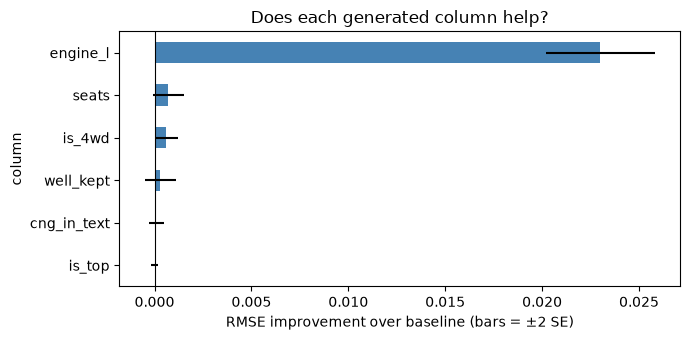

In [248]:
# ── Which generated column deserves to be kept? ──────────────────────────────
from sklearn.model_selection import RepeatedKFold, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import BaseEstimator, TransformerMixin

class EngineFill(BaseEstimator, TransformerMixin):
    """Fill missing engine_l with the median of the same brand_model, then the same Brand, then overall.
    Medians are learned from the training part of each fold only (no leakage)."""
    def fit(self, X, y=None):
        self.by_bm, self.by_brand, self.med = (X.groupby("brand_model")["engine_l"].median(),
                                              X.groupby("Brand")["engine_l"].median(),
                                              X["engine_l"].median())
        return self
    def transform(self, X):
        X = X.copy()
        X["engine_l"] = (X["engine_l"].fillna(X["brand_model"].map(self.by_bm))
                                      .fillna(X["Brand"].map(self.by_brand))
                                      .fillna(self.med))
        return X

candidates = ["engine_l", "seats", "is_4wd", "cng_in_text", "is_top", "well_kept"]

# ---------- data used for the test (the generated columns come from df_copy) ----------
X_all = df_copy.copy()
X_all["brand_model"] = X_all["Brand"].astype(str) + "|" + X_all["model"].astype(str)
X_all["km_log"]      = np.log1p(X_all["kmDriven"])
X_all["owner_ord"]   = X_all["Owner"].map({"first": 1, "second": 2, "third": 3, "fourth": 4, "fifth": 5})
y = np.log1p(X_all["AskPrice"])                       # log target: price is heavily skewed

base_num = ["Age", "km_log", "owner_ord"]

def make_model(extra):
    pre = ColumnTransformer([
        ("bm", TargetEncoder(cv=KFold(n_splits=5, shuffle=True, random_state=0)), ["brand_model"]),   # fitted inside each fold -> no leakage
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Transmission", "FuelType"]),
        ("num", "passthrough", base_num + extra),
    ])
    # seats keeps its NaNs (HistGradientBoosting handles NaN natively); engine_l is filled inside each fold
    return Pipeline([("fill", EngineFill()), ("pre", pre),
                     ("reg", HistGradientBoostingRegressor(random_state=0))])

cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)   # identical splits for every run -> paired comparison

def cv_scores(extra):
    return -cross_val_score(make_model(extra), X_all, y, cv=cv, scoring="neg_root_mean_squared_error")

base = cv_scores([])

# ---------- one row per candidate ----------
rows = []
for c in candidates:
    s      = X_all[c]
    delta  = base - cv_scores([c])                     # >0 means the column LOWERED the error
    gain   = delta.mean()
    se     = delta.std(ddof=1) / np.sqrt(len(delta))
    pres   = s.notna().mean() * 100 if c in ("engine_l", "seats") else (s == 1).mean() * 100
    rho    = s.corr(y, method="spearman")
    rows.append({
        "column": c,
        "% rows with info": round(pres, 1),            # non-null % for numeric, % of 1s for flags
        "spearman vs log(price)": round(rho, 3),
        "RMSE gain": round(gain, 4),
        "± SE": round(se, 4),
        "gain / SE": round(gain / se, 1) if se > 0 else np.nan,
    })

res = pd.DataFrame(rows).set_index("column")

# ---------- decision rule (written down in advance) ----------
def verdict(r):
    if r["RMSE gain"] > 0.005 and r["gain / SE"] > 3:   return "KEEP"
    if r["RMSE gain"] > 0.001 and r["gain / SE"] > 2:   return "MAYBE (small)"
    return "DROP"

res["decision"] = res.apply(verdict, axis=1)
res = res.sort_values("RMSE gain", ascending=False)

print(f"Baseline RMSE (log-price): {base.mean():.4f} ± {base.std():.4f}")
display(res)

# ---------- final check: chosen set vs baseline vs everything ----------
chosen = res.index[res["decision"] == "KEEP"].tolist()
for name, cols in {"baseline": [], f"chosen {chosen}": chosen, "all candidates": candidates}.items():
    s = cv_scores(cols)
    print(f"{name:45s} RMSE = {s.mean():.4f} ± {s.std():.4f}")

# ---------- plot ----------
ax = res["RMSE gain"].plot.barh(xerr=res["± SE"] * 2, figsize=(7, 3.5), color="steelblue")
ax.axvline(0, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("RMSE improvement over baseline (bars = ±2 SE)")
ax.set_title("Does each generated column help?")
plt.tight_layout(); plt.show()

In [249]:
df_copy.isna().mean()*100

Brand            0.000000
model            0.000000
Year             0.000000
Age              0.000000
kmDriven         0.000000
Transmission     0.000000
Owner            0.000000
FuelType         0.000000
PostedDate       0.000000
AdditionInfo     0.000000
AskPrice         0.000000
postedMonth      0.000000
postedYear       0.000000
engine_l        64.965815
seats           96.639079
is_4wd           0.000000
cng_in_text      0.000000
is_top           0.000000
well_kept        0.000000
dtype: float64

In [250]:
used_cars_df['engine_l'] = df_copy['engine_l']

In [251]:
used_cars_df.isna().mean()

Brand           0.000000
model           0.000000
Year            0.000000
Age             0.000000
kmDriven        0.000000
Transmission    0.000000
Owner           0.000000
FuelType        0.000000
PostedDate      0.000000
AdditionInfo    0.000000
AskPrice        0.000000
postedMonth     0.000000
postedYear      0.000000
engine_l        0.649658
dtype: float64

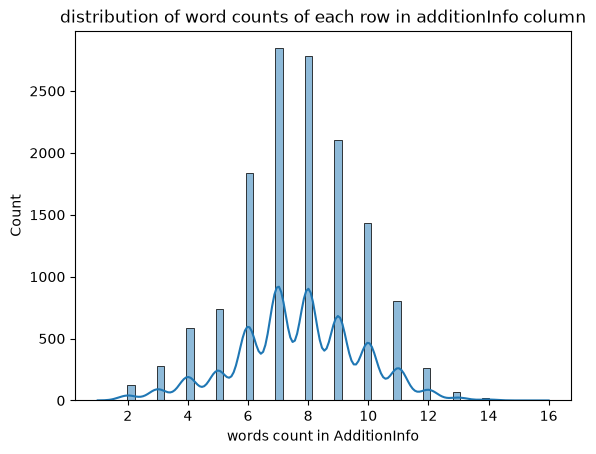

In [252]:
plt.subplots()
sns.histplot(data=pd.DataFrame(used_cars_df['AdditionInfo'].str.split().map(lambda x: len(x))),
             x='AdditionInfo',
             kde=True)

plt.title('distribution of word counts of each row in additionInfo column')
plt.xlabel('words count in AdditionInfo')
plt.ylabel('Count')
plt.show()

# Explortary Data Analysis **EDA** 

#### Categorical distributions and Exploration

In [253]:
used_cars_df.info()

<class 'pandas.DataFrame'>
Index: 13895 entries, 0 to 14992
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         13895 non-null  str    
 1   model         13895 non-null  str    
 2   Year          13895 non-null  int64  
 3   Age           13895 non-null  int64  
 4   kmDriven      13895 non-null  float64
 5   Transmission  13895 non-null  str    
 6   Owner         13895 non-null  str    
 7   FuelType      13895 non-null  str    
 8   PostedDate    13895 non-null  str    
 9   AdditionInfo  13895 non-null  str    
 10  AskPrice      13895 non-null  float64
 11  postedMonth   13895 non-null  int64  
 12  postedYear    13895 non-null  int64  
 13  engine_l      4868 non-null   float64
dtypes: float64(3), int64(4), str(7)
memory usage: 1.6 MB


In [254]:
used_cars_df['brand_model'] = used_cars_df['Brand'] + ',' + used_cars_df['model'].str.replace(r'[\s-]', '', regex=True)
display("preview of the new concatenated column")
display(used_cars_df[['brand_model', 'Brand', 'model']].head(10))
display('New unique counts in brand_model column')
display(used_cars_df[['brand_model', 'Brand', 'model']].nunique())

'preview of the new concatenated column'

,brand_model,Brand,model
0,"Honda,City",Honda,City
1,"Toyota,Innova",Toyota,Innova
2,"Volkswagen,VentoTest",Volkswagen,VentoTest
3,"Maruti Suzuki,Swift",Maruti Suzuki,Swift
4,"Maruti Suzuki,Baleno",Maruti Suzuki,Baleno
5,"BMW,X3",BMW,X3
6,"Toyota,Innova",Toyota,Innova
7,"BMW,5Series",BMW,5 Series
8,"Maruti Suzuki,marutisuzukidzire",Maruti Suzuki,maruti-suzuki-dzire
9,"Ford,Ecosport",Ford,Ecosport


'New unique counts in brand_model column'

brand_model    414
Brand           42
model          434
dtype: int64

In [255]:
from fixBrandModel import fix_brand_model

used_cars_df = fix_brand_model(used_cars_df)

In [256]:
temp = used_cars_df.drop_duplicates(subset='brand_model')
mask = temp.duplicated(subset='model', keep=False).tolist()

temp[mask] # Mahindra <- Ssangyon & the Rexton was common between them

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model


In [257]:
cat_cols = used_cars_df.drop(columns=['AdditionInfo', 'PostedDate']).select_dtypes(include='str').columns.to_list()
cat_cols

['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'brand_model']

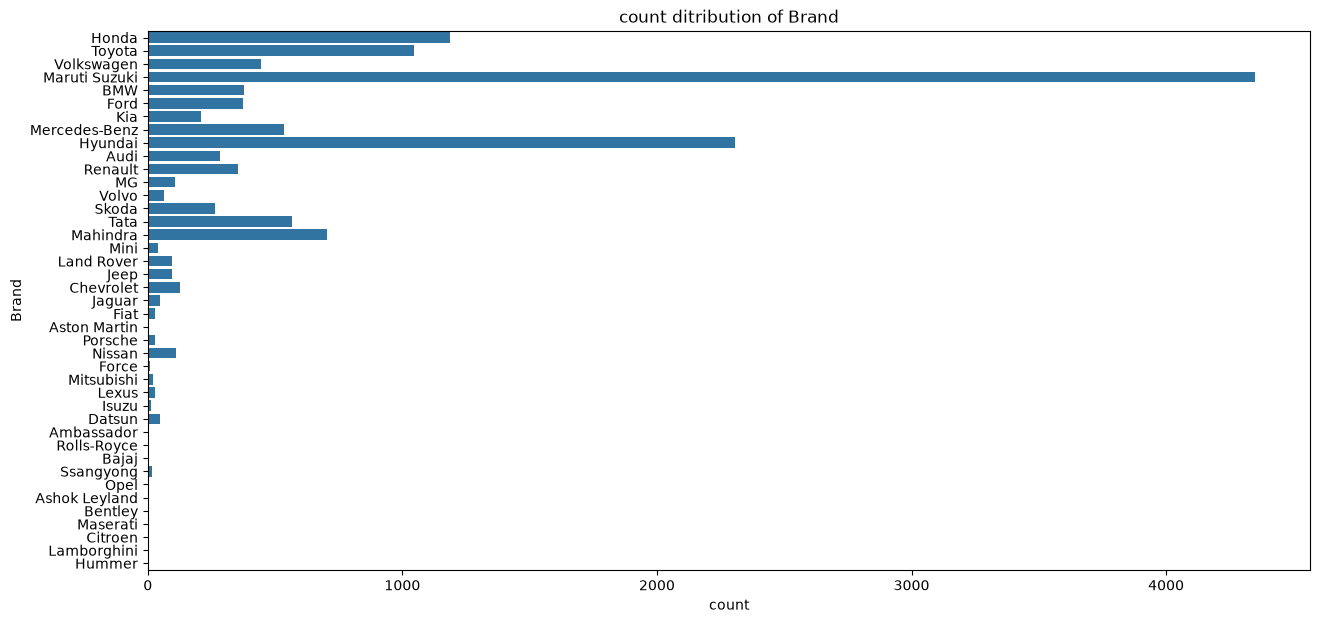

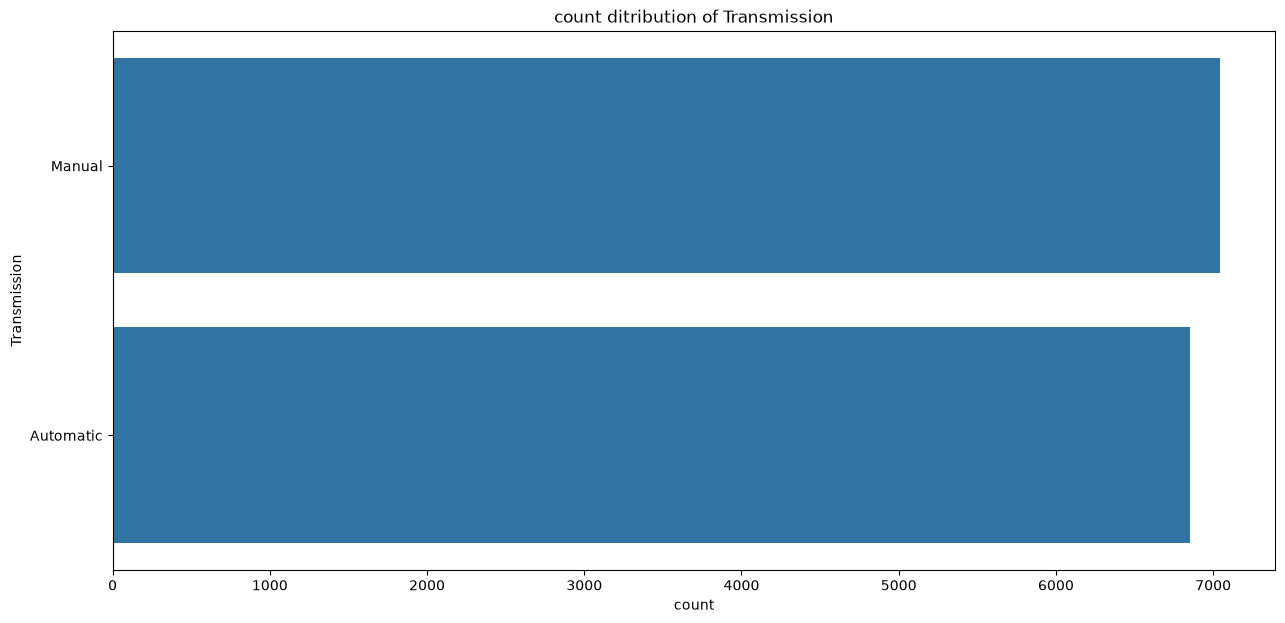

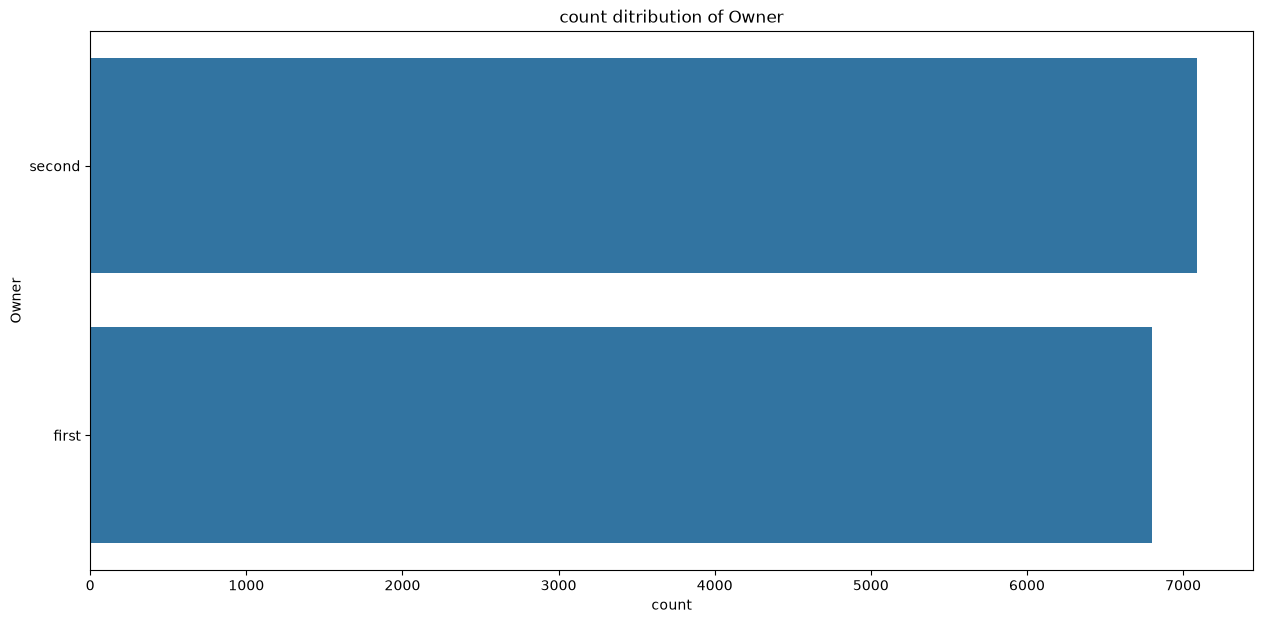

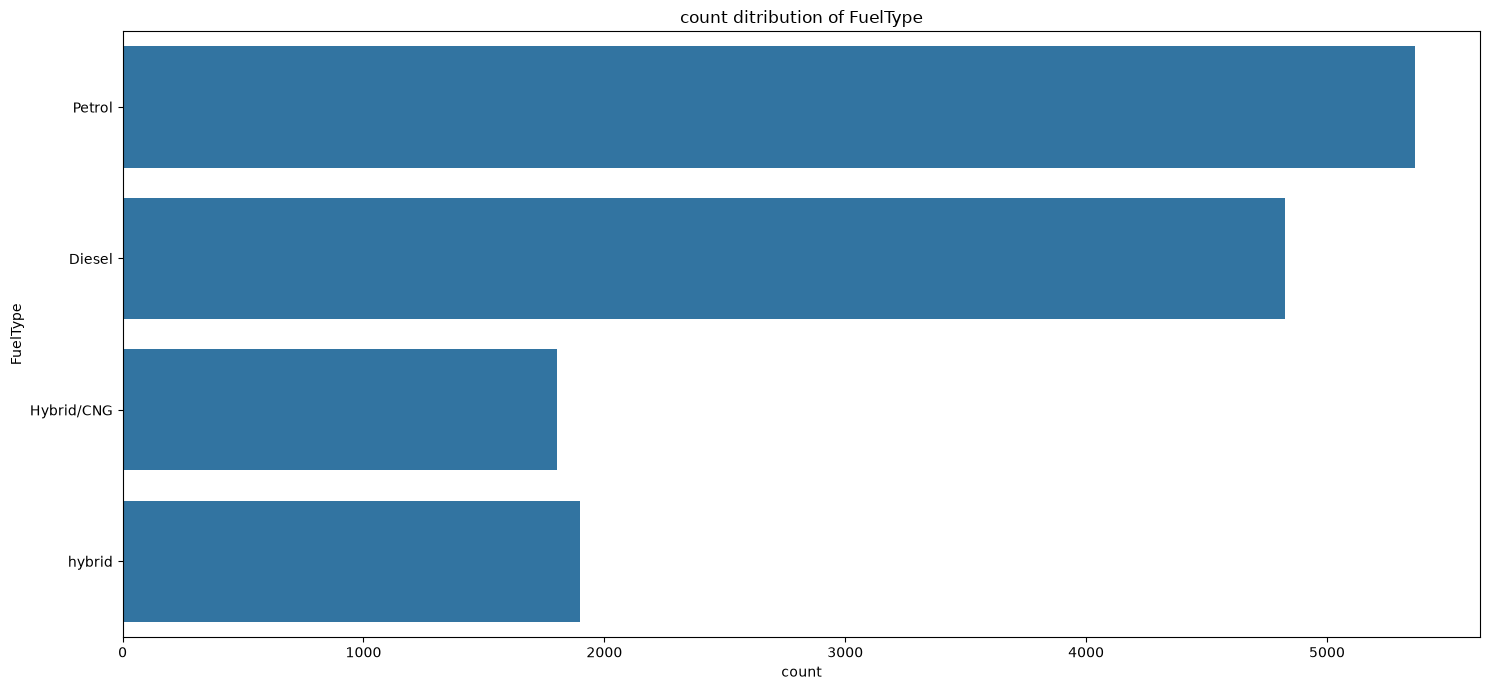

In [258]:
for col in cat_cols:
    if col == 'model' or col == 'brand_model': 
        continue
    plt.figure(figsize=(15,7))
    sns.countplot(data=used_cars_df, y=col)
    plt.title(f'count ditribution of {col}')

plt.tight_layout()
plt.show()


In [259]:
for col in cat_cols:
    if col == 'model':
        continue
    top10_count = used_cars_df[col].value_counts().sort_values(ascending=False).head(10).index.tolist() 
    print(f'top 10 counts in {col} -descending- :\n', top10_count)


top 10 counts in Brand -descending- :
 ['Maruti Suzuki', 'Hyundai', 'Honda', 'Toyota', 'Mahindra', 'Tata', 'Mercedes-Benz', 'Volkswagen', 'BMW', 'Ford']
top 10 counts in Transmission -descending- :
 ['Manual', 'Automatic']
top 10 counts in Owner -descending- :
 ['second', 'first']
top 10 counts in FuelType -descending- :
 ['Petrol', 'Diesel', 'hybrid', 'Hybrid/CNG']
top 10 counts in brand_model -descending- :
 ['Maruti Suzuki,Wagon R', 'Honda,City', 'Maruti Suzuki,Ertiga', 'Maruti Suzuki,Swift', 'Maruti Suzuki,Swift Dzire', 'Hyundai,Creta', 'Maruti Suzuki,Celerio', 'Hyundai,i10', 'Maruti Suzuki,Eeco', 'Hyundai,Grand i10']


In [260]:
postedMonth = used_cars_df['PostedDate'].str.split('-').str[0]
postedMonth.value_counts()

PostedDate
Nov    12223
Dec      746
Oct      629
Sep      162
Aug       67
Jul       29
Jun       20
Apr        8
May        6
Jan        2
Feb        2
Mar        1
Name: count, dtype: int64

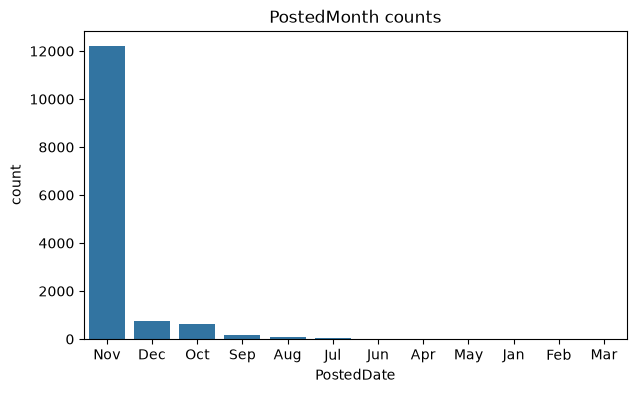

In [261]:
plt.figure(figsize=(7,4))
sns.barplot(postedMonth.value_counts())
plt.title('PostedMonth counts')
plt.show()

#### Categorical-Categorical relationships 

In [262]:
counts = used_cars_df.groupby(['Brand','model']).size().reset_index(name='count')
counts = counts.sort_values(by=['Brand', 'model'], ascending=[True, False])
counts.groupby('Brand').head(3) 

,Brand,model,count
0,Ambassador,Ambassador,3
1,Ashok Leyland,Stile,1
2,Aston Martin,Vanquish,1
16,Audi,RS7,1
15,Audi,Q7,28
...,...,...,...
382,Volkswagen,Vento,136
381,Volkswagen,Tiguan All Space,2
391,Volvo,XC90,9
390,Volvo,XC60,19


In [263]:
unique_brand_model_df = used_cars_df.drop_duplicates(subset=['Brand', 'model'])
unique_brand_model_df.pivot_table(index='Brand', columns='Transmission', aggfunc='size', fill_value=0)

Transmission,Automatic,Manual
Brand,,
Ambassador,0,1
Ashok Leyland,1,0
Aston Martin,1,0
Audi,14,0
BMW,20,0
Bajaj,1,0
Bentley,1,0
Chevrolet,4,8
Citroen,1,0


In [264]:
unique_rows_df = used_cars_df.drop_duplicates()
unique_rows_df.pivot_table(index='brand_model', columns='Transmission', aggfunc='size', fill_value=0)


Transmission,Automatic,Manual
brand_model,,
"Ambassador,Ambassador",0,3
"Ashok Leyland,Stile",1,0
"Aston Martin,Vanquish",1,0
"Audi,2.9 Sportback",1,0
"Audi,A3",18,0
...,...,...
"Volvo,S90",8,0
"Volvo,V40 Cross Country",4,0
"Volvo,XC40",4,0


In [265]:
unique_rows_df.pivot_table(index='brand_model', columns='FuelType', aggfunc='size', fill_value=0)

FuelType,Diesel,Hybrid/CNG,Petrol,hybrid
brand_model,,,,
"Ambassador,Ambassador",0,0,3,0
"Ashok Leyland,Stile",0,1,0,0
"Aston Martin,Vanquish",0,0,1,0
"Audi,2.9 Sportback",0,0,1,0
"Audi,A3",16,0,2,0
...,...,...,...,...
"Volvo,S90",7,1,0,0
"Volvo,V40 Cross Country",3,0,1,0
"Volvo,XC40",3,0,1,0


In [266]:
used_cars_df['postedYear'].value_counts()

postedYear
2024    13892
2023        3
Name: count, dtype: int64

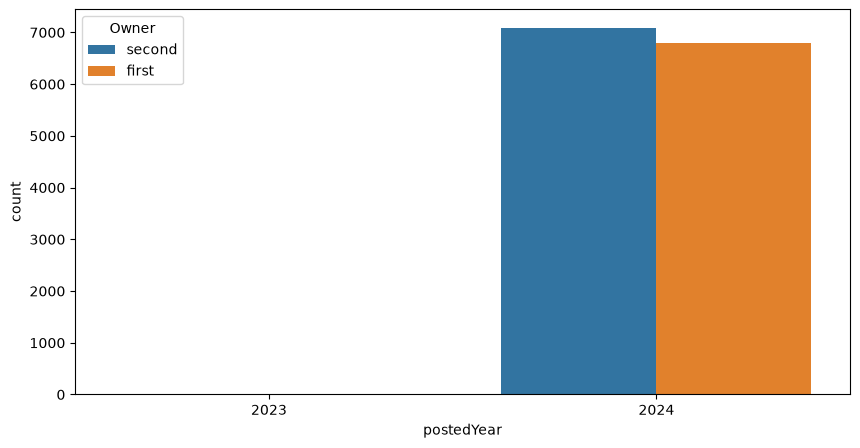

In [267]:
plt.figure(figsize=(10,5))
sns.countplot(data=used_cars_df, x='postedYear', hue='Owner')
plt.show()

#### Numerical distributions and Exploration

In [268]:
num_cols = used_cars_df.select_dtypes(include=np.number).columns.tolist()
skip_cols_plt = ['Year', 'postedYear']
num_cols

['Year',
 'Age',
 'kmDriven',
 'AskPrice',
 'postedMonth',
 'postedYear',
 'engine_l']

In [269]:
used_cars_df['engine_l'].isna().mean()*100

np.float64(64.96581504138179)

In [270]:
by_model = used_cars_df.groupby('brand_model')['engine_l'].transform('median')
by_brand = used_cars_df.groupby('Brand')['engine_l'].transform('median')

used_cars_df['engine_l_imputed'] = used_cars_df['engine_l'].isna().astype(int)

used_cars_df['engine_l'] = used_cars_df['engine_l'].fillna(by_model).fillna(by_brand).fillna(used_cars_df['engine_l'].median())

In [271]:
used_cars_df.isna().mean()*100

Brand               0.0
model               0.0
Year                0.0
Age                 0.0
kmDriven            0.0
Transmission        0.0
Owner               0.0
FuelType            0.0
PostedDate          0.0
AdditionInfo        0.0
AskPrice            0.0
postedMonth         0.0
postedYear          0.0
engine_l            0.0
brand_model         0.0
engine_l_imputed    0.0
dtype: float64

In [272]:
used_cars_df[['engine_l', 'engine_l_imputed']]

,engine_l,engine_l_imputed
0,1.5,1
1,2.5,0
2,1.5,1
3,1.2,1
4,1.2,1
...,...,...
14988,1.0,1
14989,2.0,0
14990,1.2,1
14991,1.2,0


In [273]:
test_integrity = used_cars_df['postedYear'] - used_cars_df['Year']
age_diff = test_integrity - used_cars_df['Age'] 
used_cars_df[age_diff != 0]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model,engine_l_imputed
3898,Toyota,Corolla Altis,2012,12,116000.0,Manual,second,Petrol,Dec-23,"Toyota Corolla Altis 1.8 J Plus, 2012, Petrol",525000.0,12,2023,1.8,"Toyota,Corolla Altis",0
4153,Mercedes-Benz,C-Class,2020,4,59001.0,Automatic,first,Diesel,Dec-23,"Mercedes-Benz C-Class 2.0 220d Progressive, 20...",3690000.0,12,2023,2.0,"Mercedes-Benz,C-Class",0
4558,Maruti Suzuki,Swift Dzire,2017,7,77000.0,Manual,second,Diesel,Dec-23,"Maruti Suzuki Swift Dzire VDI (O), 2017, Diesel",600000.0,12,2023,1.2,"Maruti Suzuki,Swift Dzire",1


In [274]:
used_cars_df[used_cars_df.postedYear == 2023]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model,engine_l_imputed
3898,Toyota,Corolla Altis,2012,12,116000.0,Manual,second,Petrol,Dec-23,"Toyota Corolla Altis 1.8 J Plus, 2012, Petrol",525000.0,12,2023,1.8,"Toyota,Corolla Altis",0
4153,Mercedes-Benz,C-Class,2020,4,59001.0,Automatic,first,Diesel,Dec-23,"Mercedes-Benz C-Class 2.0 220d Progressive, 20...",3690000.0,12,2023,2.0,"Mercedes-Benz,C-Class",0
4558,Maruti Suzuki,Swift Dzire,2017,7,77000.0,Manual,second,Diesel,Dec-23,"Maruti Suzuki Swift Dzire VDI (O), 2017, Diesel",600000.0,12,2023,1.2,"Maruti Suzuki,Swift Dzire",1


In [275]:
# The Dataset has some errors with dealing with age of cars posted in 2023

issued_rows_idx = used_cars_df[used_cars_df.postedYear == 2023].index.tolist()

used_cars_df['Age'] = np.where(used_cars_df.postedYear == 2023, used_cars_df.Age-1, used_cars_df.Age)

In [276]:
used_cars_df.loc[issued_rows_idx]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model,engine_l_imputed
3898,Toyota,Corolla Altis,2012,11,116000.0,Manual,second,Petrol,Dec-23,"Toyota Corolla Altis 1.8 J Plus, 2012, Petrol",525000.0,12,2023,1.8,"Toyota,Corolla Altis",0
4153,Mercedes-Benz,C-Class,2020,3,59001.0,Automatic,first,Diesel,Dec-23,"Mercedes-Benz C-Class 2.0 220d Progressive, 20...",3690000.0,12,2023,2.0,"Mercedes-Benz,C-Class",0
4558,Maruti Suzuki,Swift Dzire,2017,6,77000.0,Manual,second,Diesel,Dec-23,"Maruti Suzuki Swift Dzire VDI (O), 2017, Diesel",600000.0,12,2023,1.2,"Maruti Suzuki,Swift Dzire",1


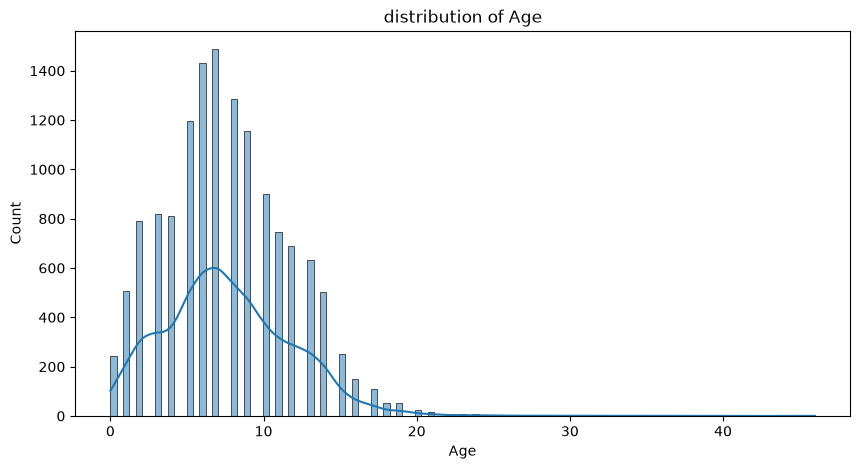

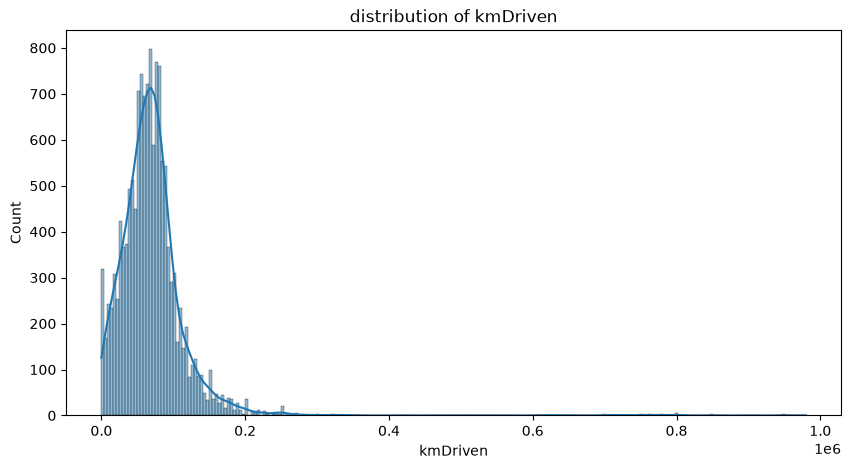

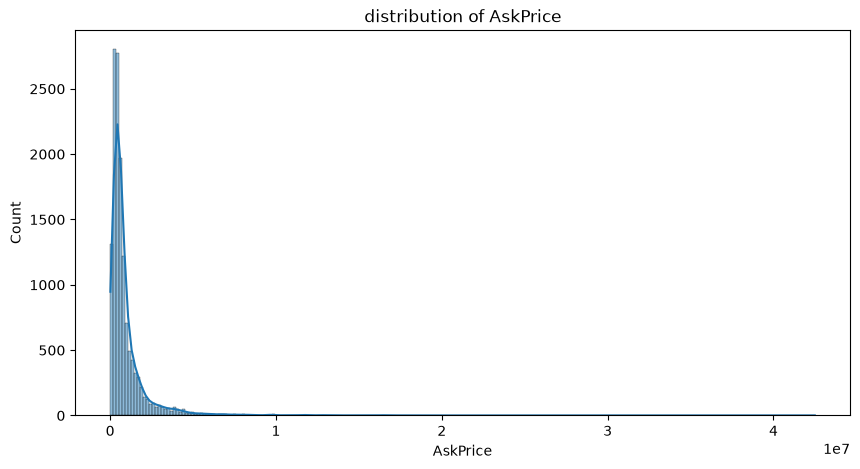

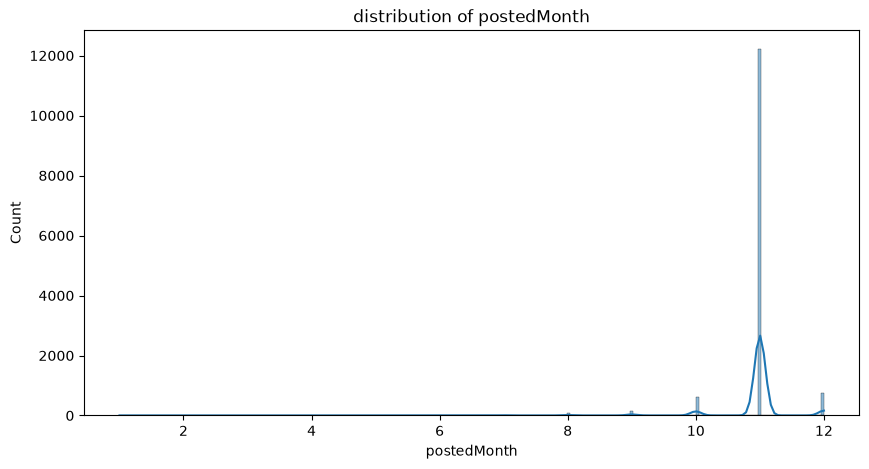

In [277]:
for col in num_cols: 
    if col in skip_cols_plt or col in ['engine_l', 'engine_l_imputed']: 
        continue
    plt.figure(figsize=(10,5))
    sns.histplot(used_cars_df[col], kde=True)
    plt.title(f'distribution of {col}')

plt.show()

In [278]:
postedMonth.value_counts() 

PostedDate
Nov    12223
Dec      746
Oct      629
Sep      162
Aug       67
Jul       29
Jun       20
Apr        8
May        6
Jan        2
Feb        2
Mar        1
Name: count, dtype: int64

#### Numerical-Numerical relationships

<Figure size 1000x500 with 0 Axes>

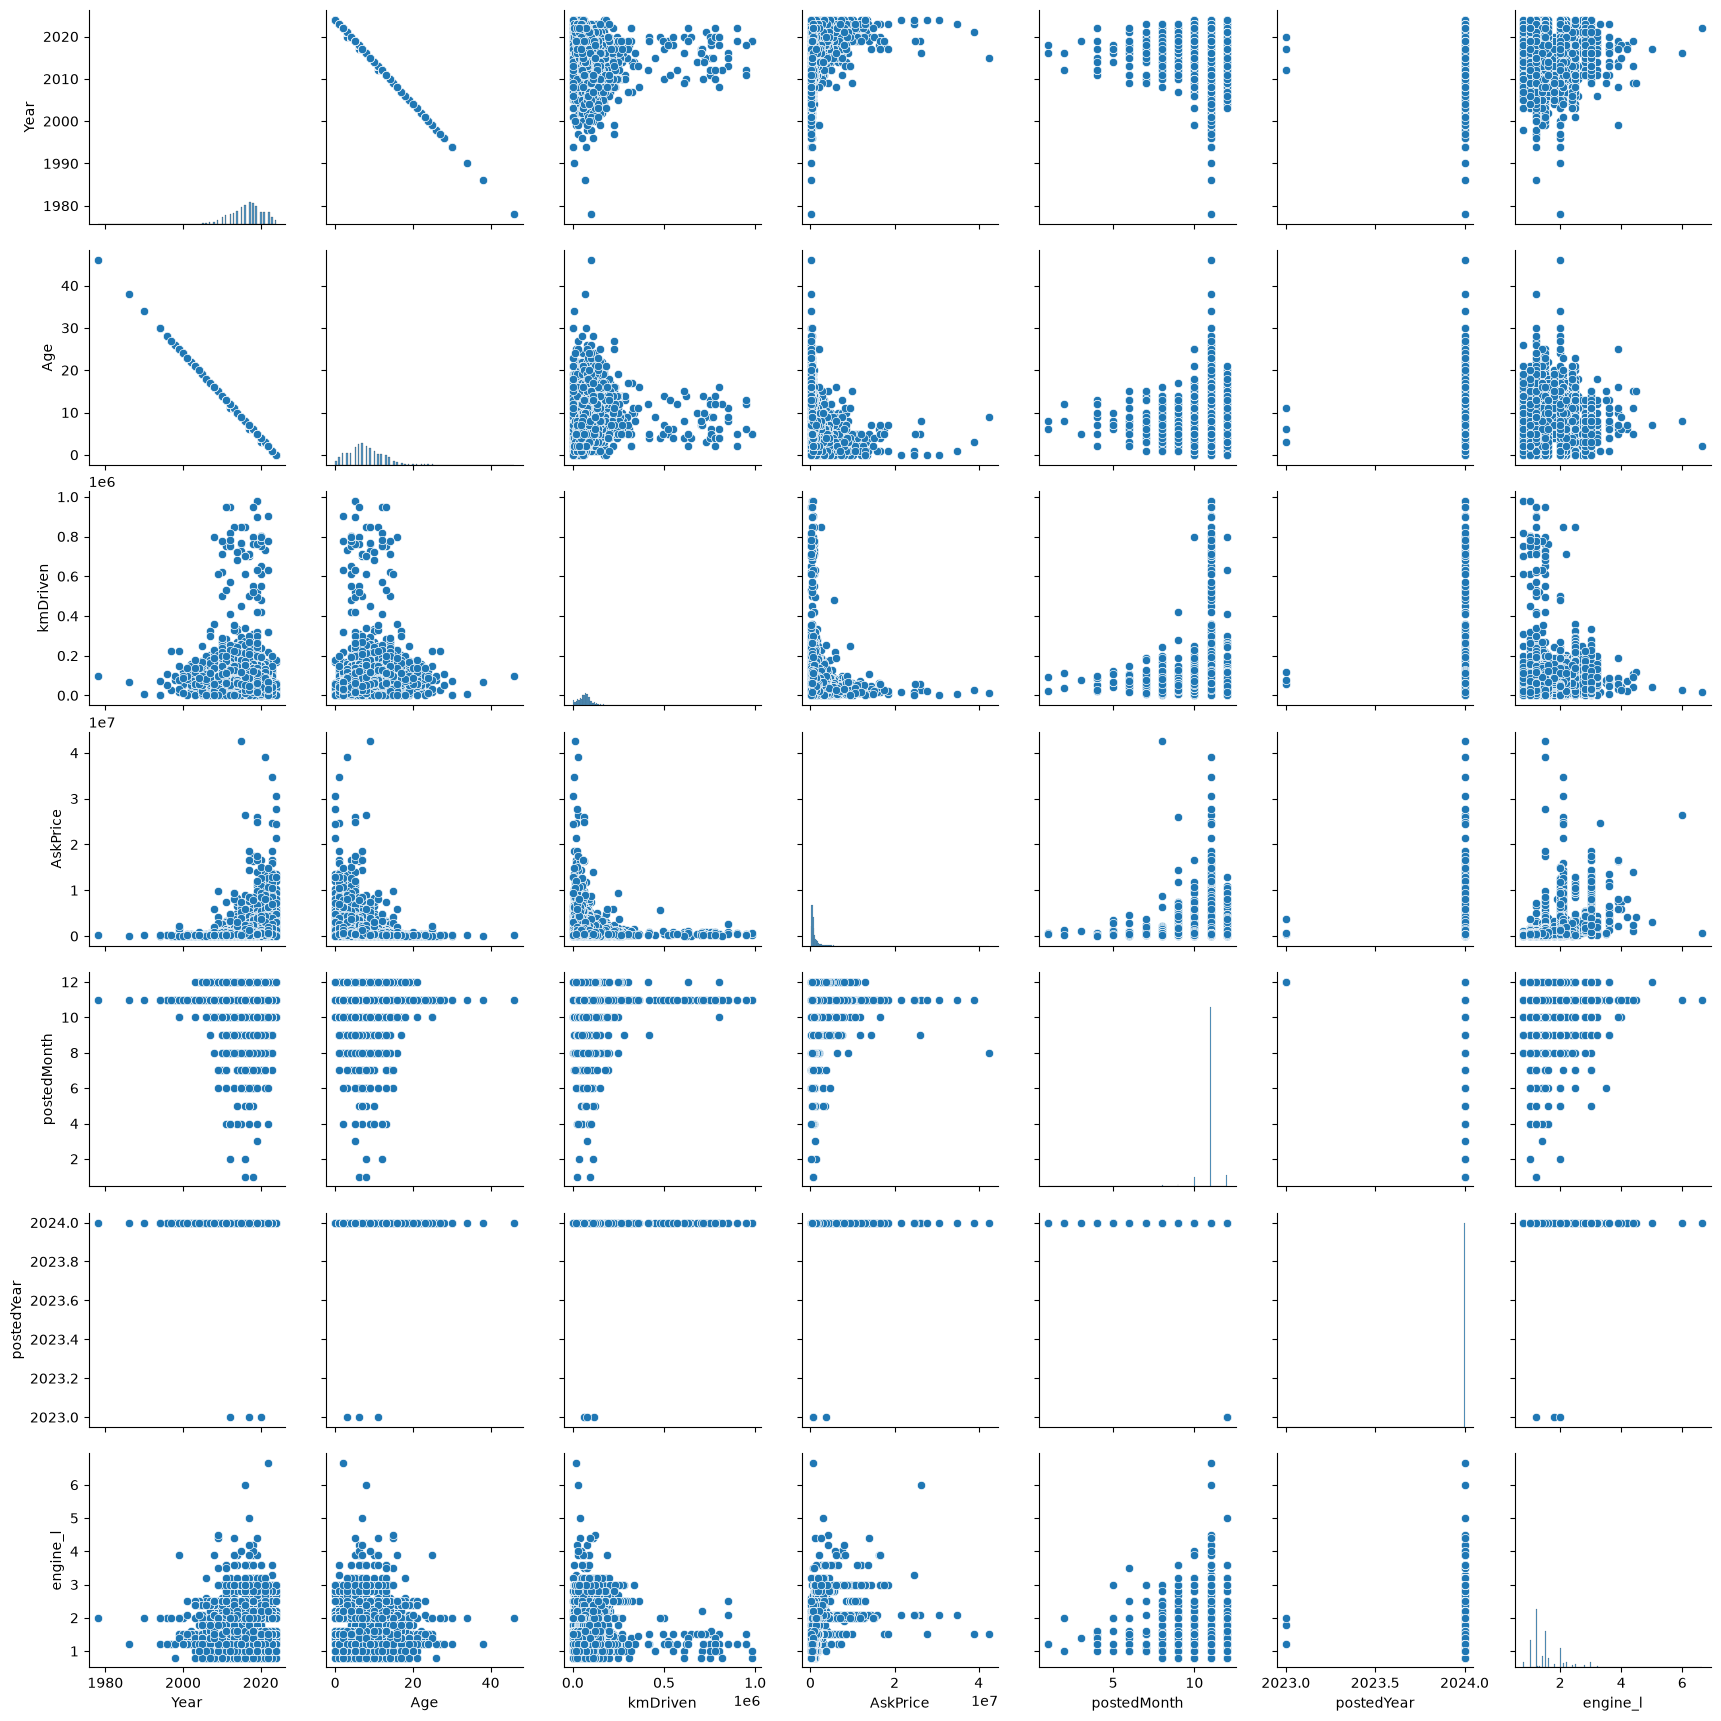

In [279]:
plt.figure(figsize=(10,5))
sns.pairplot(used_cars_df[num_cols])

<Axes: >

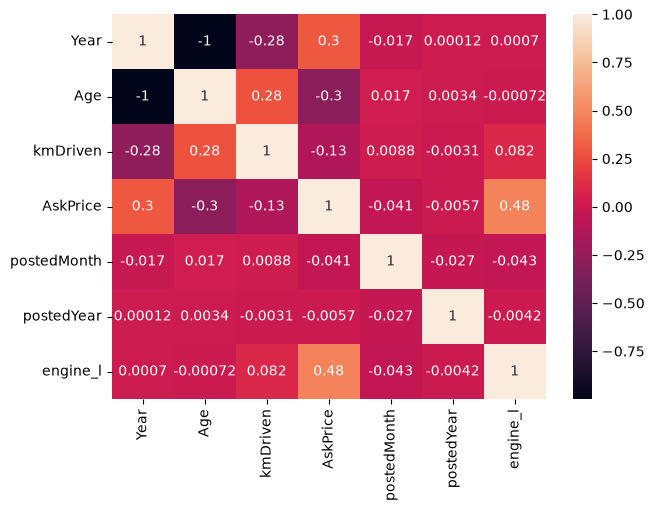

In [280]:
plt.figure(figsize=(7,5))
sns.heatmap(used_cars_df[num_cols].corr(), annot=True)

In [281]:
used_cars_df['kmDriven/year']= used_cars_df['kmDriven']/np.max(used_cars_df['Age'],1)
num_cols.append('kmDriven/year')
display(used_cars_df[num_cols].corr()['AskPrice'])
display(used_cars_df[num_cols].corr(method='spearman')['AskPrice'])

ValueError: No axis named 1 for object type Series

In [ ]:
used_cars_df.isna().sum()

Brand               0
model               0
Year                0
Age                 0
kmDriven            0
Transmission        0
Owner               0
FuelType            0
PostedDate          0
AdditionInfo        0
AskPrice            0
postedMonth         0
postedYear          0
engine_l            0
brand_model         0
engine_l_imputed    0
kmDriven/year       0
dtype: int64

In [ ]:
used_cars_df.loc[used_cars_df['kmDriven/year'].isna()]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model,engine_l_imputed,kmDriven/year


In [ ]:
used_cars_df.fillna({'kmDriven/year':0}, inplace=True).loc[used_cars_df.Age]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model,engine_l_imputed,kmDriven/year
23,Audi,A3,2015,9,42000.0,Automatic,second,Diesel,Nov-24,"Audi A3 2.0 35 TDI Attraction, 2015, Diesel",1050000.0,11,2024,2.0,"Audi,A3",0,4200.000000
15,Hyundai,Xcent,2018,6,130000.0,Manual,second,Diesel,Nov-24,"Hyundai Xcent S 1.2 OPT, 2018, Diesel",330000.0,11,2024,1.2,"Hyundai,Xcent",0,18571.428571
14,Mercedes-Benz,GLE Coupe,2021,3,32000.0,Automatic,second,Petrol,Oct-24,Mercedes-Benz GLE COUPE 3.0 53 AMG 4MATIC Plus...,11800000.0,10,2024,3.0,"Mercedes-Benz,GLE Coupe",0,8000.000000
7,BMW,5 Series,2019,5,25000.0,Automatic,second,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0,11,2024,3.0,"BMW,5 Series",0,4166.666667
5,BMW,X3,2014,10,83000.0,Automatic,first,Diesel,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0,11,2024,2.0,"BMW,X3",0,7545.454545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,Volkswagen,Vento,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,11,2024,1.5,"Volkswagen,Vento",1,5149.733333
7,BMW,5 Series,2019,5,25000.0,Automatic,second,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel",5950000.0,11,2024,3.0,"BMW,5 Series",0,4166.666667
13,Toyota,Corolla,2007,17,121931.0,Automatic,second,Petrol,Nov-24,Top End Fully Loaded Automatic Corolla with ...,201350.0,11,2024,1.8,"Toyota,Corolla",1,6773.944444
5,BMW,X3,2014,10,83000.0,Automatic,first,Diesel,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel",1350000.0,11,2024,2.0,"BMW,X3",0,7545.454545


In [ ]:
used_cars_df.isna().sum()

Brand               0
model               0
Year                0
Age                 0
kmDriven            0
Transmission        0
Owner               0
FuelType            0
PostedDate          0
AdditionInfo        0
AskPrice            0
postedMonth         0
postedYear          0
engine_l            0
brand_model         0
engine_l_imputed    0
kmDriven/year       0
dtype: int64

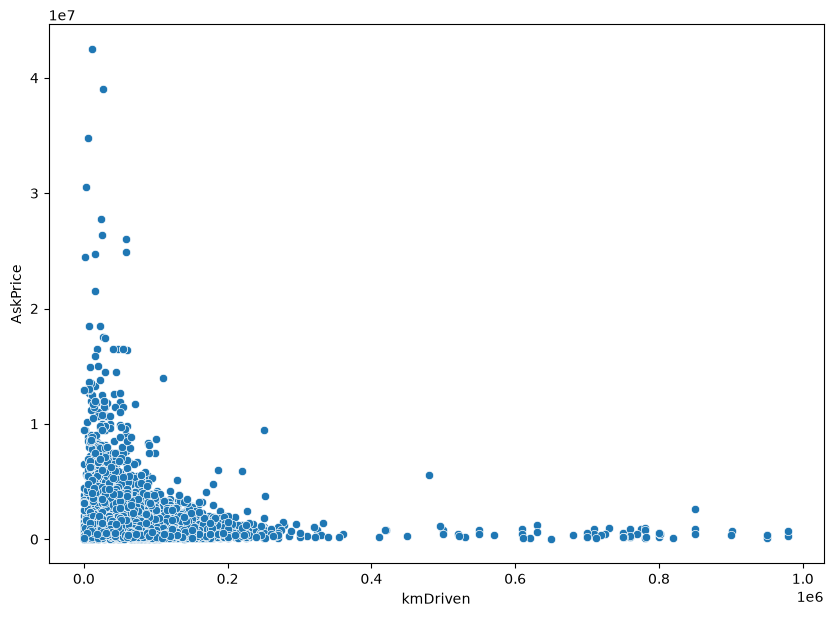

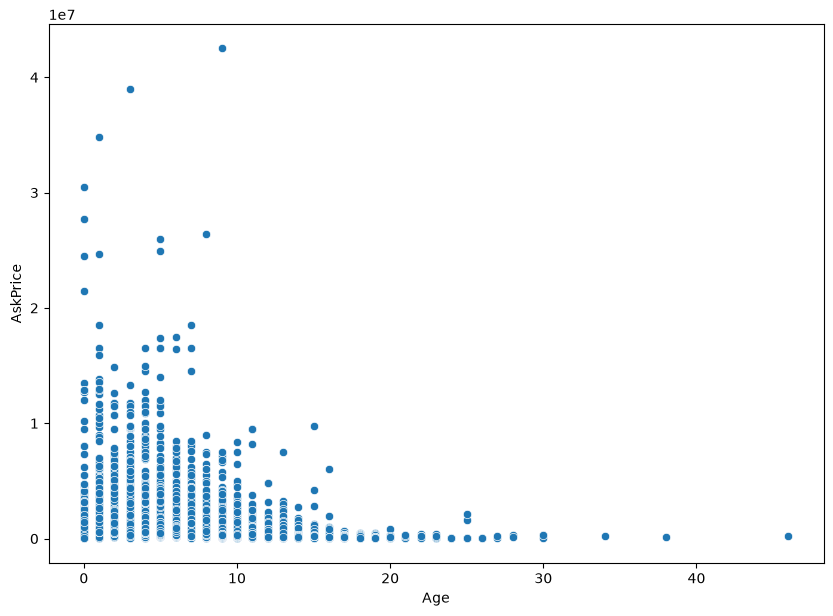

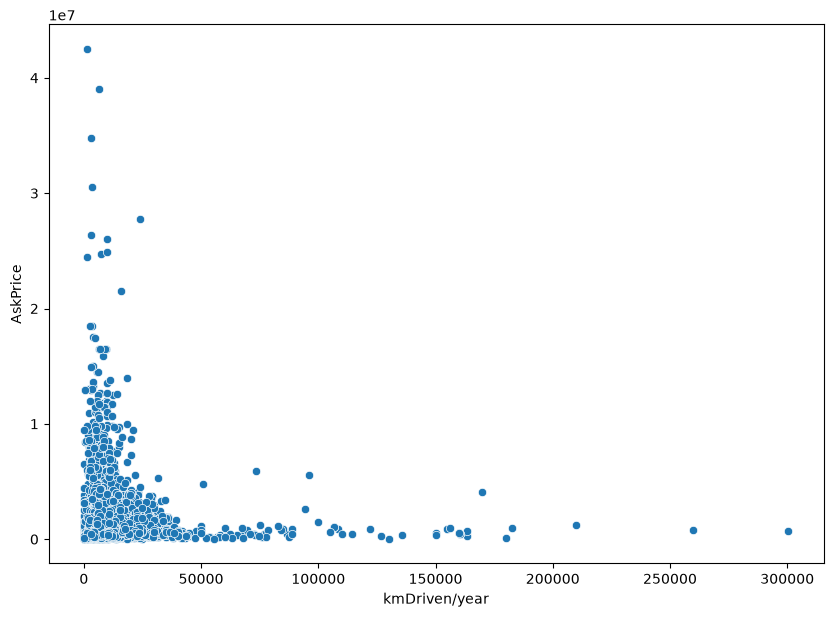

In [ ]:
for col in ['kmDriven', 'Age', 'kmDriven/year']:
    plt.figure(figsize=(10,7))
    sns.scatterplot(data=used_cars_df, x=col, y='AskPrice')
    plt.show()

#### Categorical-Numerical relationships

In [ ]:
cat_cols, num_cols

(['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'brand_model'],
 ['Year',
  'Age',
  'kmDriven',
  'AskPrice',
  'postedMonth',
  'postedYear',
  'engine_l',
  'kmDriven/year'])

In [ ]:
target_cat_cols=['Transmission','Owner','FuelType']

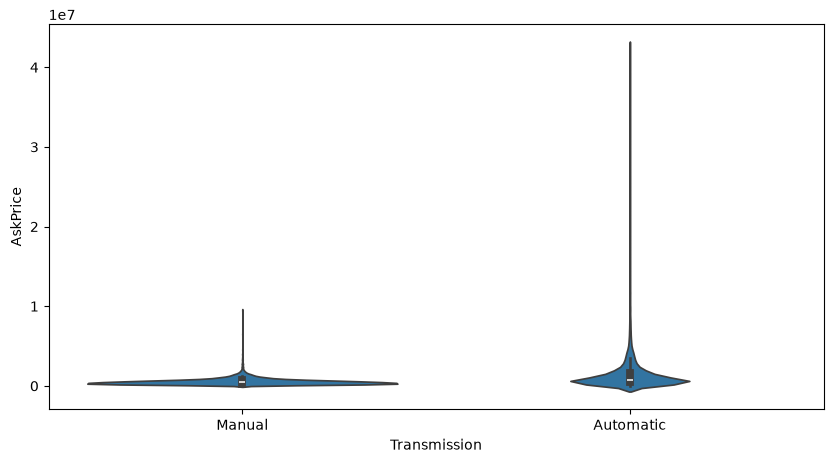

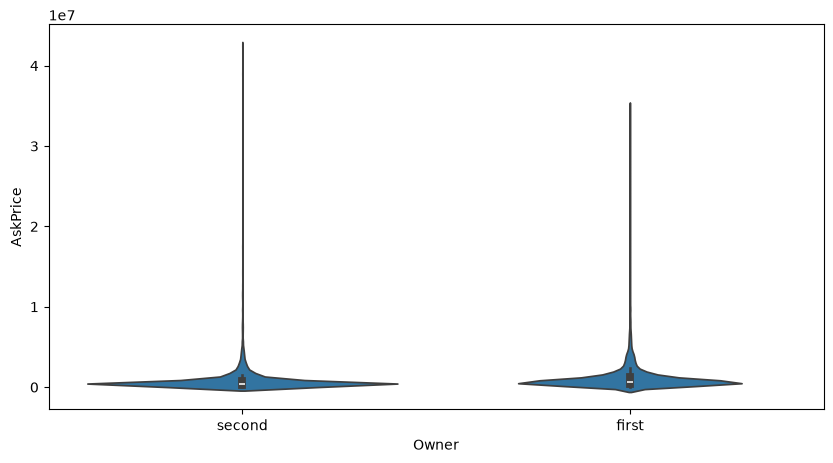

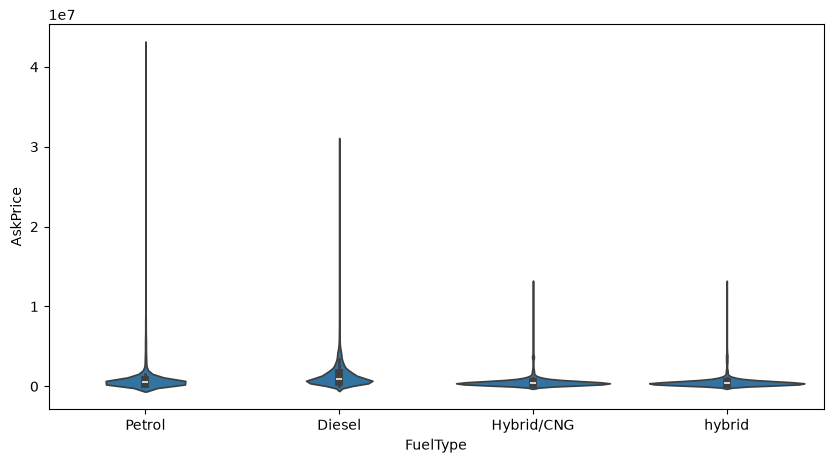

In [ ]:
for col in target_cat_cols:
    plt.figure(figsize=(10,5))
    sns.violinplot(used_cars_df, x=col, y='AskPrice')
    plt.show()

<Figure size 1000x500 with 0 Axes>

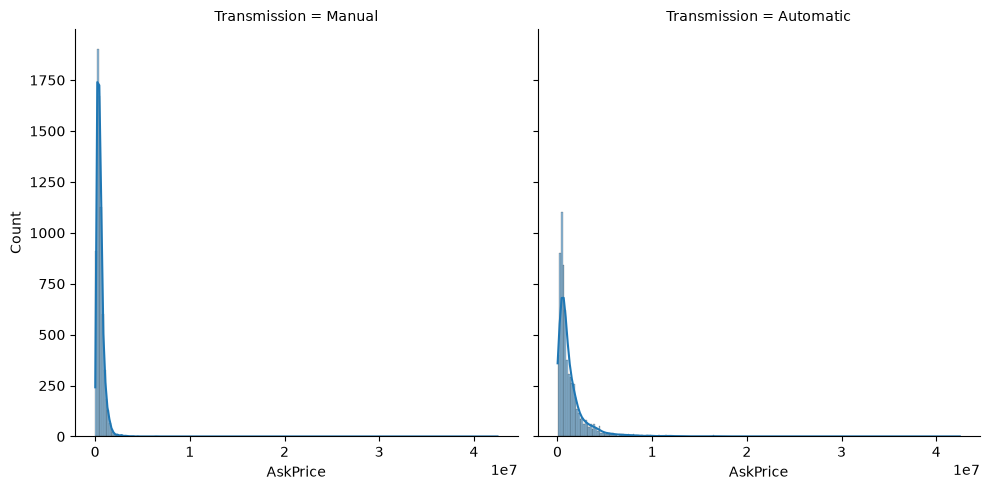

<Figure size 1000x500 with 0 Axes>

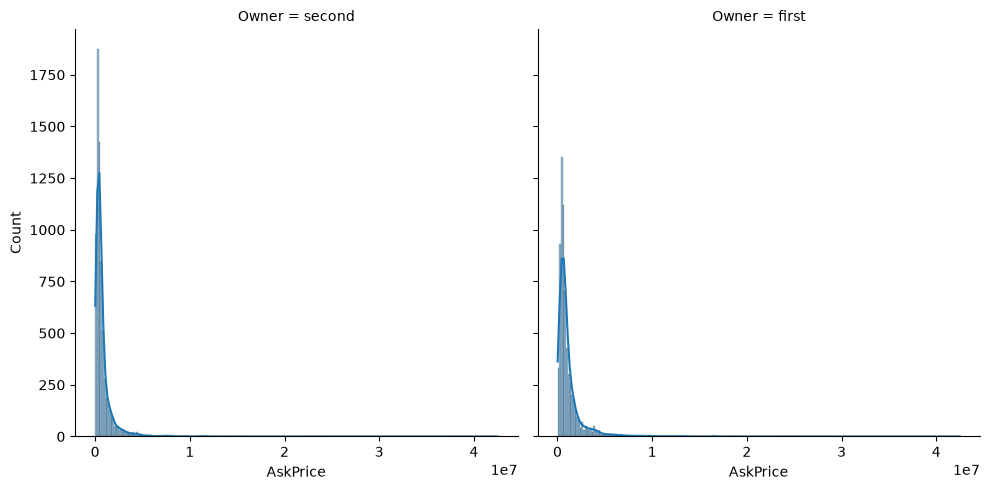

<Figure size 1000x500 with 0 Axes>

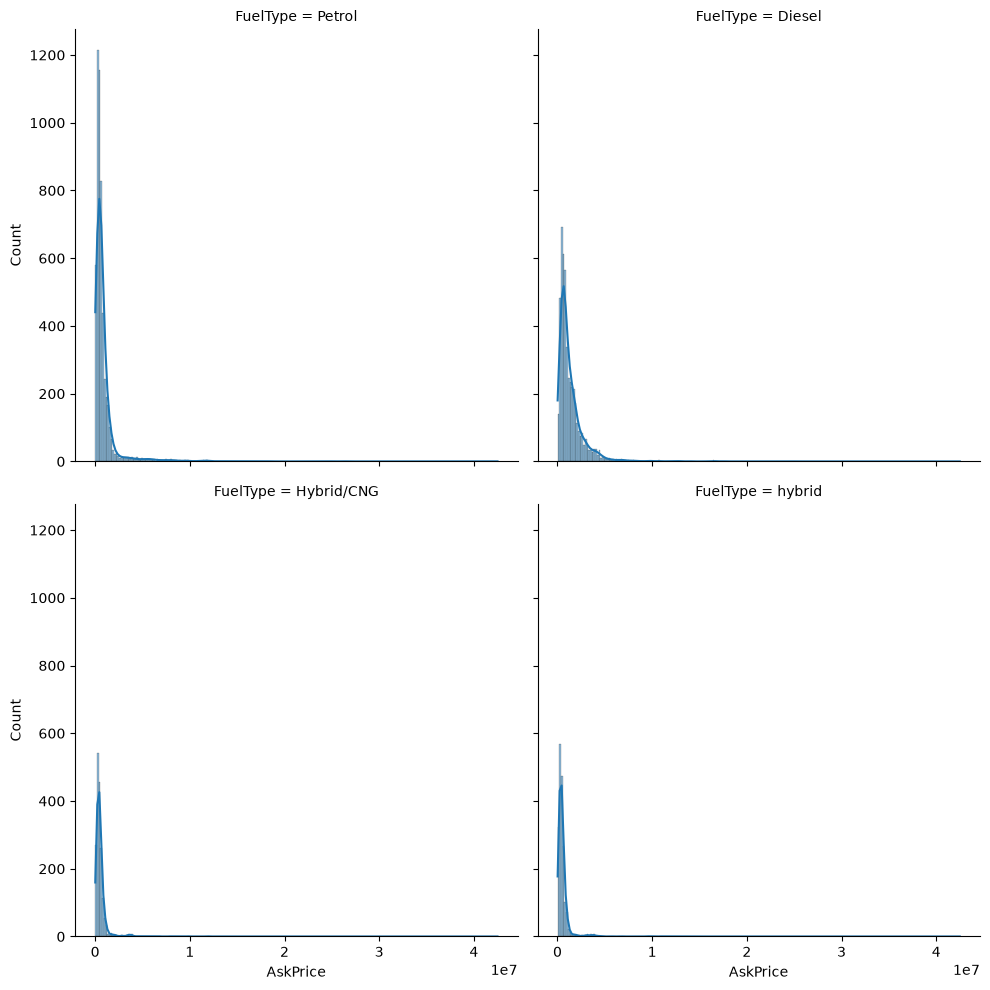

In [ ]:
for col in target_cat_cols:
    plt.figure(figsize=(10,5))
    sns.displot(used_cars_df, x='AskPrice', col=col, kde=True, col_wrap=2)
    plt.show()    

In [ ]:
for col in target_cat_cols: 
    display(used_cars_df.groupby(col)['AskPrice'].agg([np.median, np.mean]))

,median,mean
Transmission,,
Automatic,780000.0,1.446555e+06
Manual,450000.0,5.336969e+05


,median,mean
Owner,,
first,675000.0,1.191752e+06
second,450000.0,7.844950e+05


,median,mean
FuelType,,
Diesel,889000.0,1.389784e+06
Hybrid/CNG,411000.0,5.511554e+05
Petrol,510000.0,9.238626e+05
hybrid,395000.0,5.339780e+05


In [ ]:
temp = used_cars_df.groupby(['Brand','brand_model']).\
    agg({'AskPrice':[np.median, np.mean, np.std]}).\
    reset_index()

temp.columns = ['Brand', 'brand_model', 'AskPrice median', 'AskPrice mean', 'AskPrice std']
temp = temp.sort_values(by=['AskPrice median', 'AskPrice mean', 'AskPrice std'], ascending=[False, False, True])
temp = temp.groupby('Brand').head(3).sort_values('Brand').reset_index(drop=True)
temp 

,Brand,brand_model,AskPrice median,AskPrice mean,AskPrice std
0,Ambassador,"Ambassador,Ambassador",421000.0,5.251997e+05,3.525905e+05
1,Ashok Leyland,"Ashok Leyland,Stile",32000.0,3.200000e+04,0.000000e+00
2,Aston Martin,"Aston Martin,Vanquish",26400000.0,2.640000e+07,0.000000e+00
3,Audi,"Audi,Q3 Sportback",4800000.0,4.800000e+06,4.700000e+06
4,Audi,"Audi,Q2",3500000.0,3.500000e+06,0.000000e+00
...,...,...,...,...,...
95,Volkswagen,"Volkswagen,Tiguan All Space",3025000.0,3.025000e+06,1.750000e+05
96,Volkswagen,"Volkswagen,Beetle",2124500.0,2.124500e+06,6.755000e+05
97,Volvo,"Volvo,XC90",3749000.0,3.713666e+06,1.872792e+06
98,Volvo,"Volvo,S90",3266666.5,3.450347e+06,8.447830e+05


# Saving of final `df`

In [ ]:
from pathlib import Path

folder_path = Path('../modified_data')
folder_path.mkdir(parents=True, exist_ok=True)

used_cars_df.to_csv(folder_path / 'cleaned_used_cars_dataset.csv', index=False)

In [ ]:
used_cars_df.loc[used_cars_df.Year < 2000]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice,postedMonth,postedYear,engine_l,brand_model,engine_l_imputed,kmDriven/year
204,Maruti Suzuki,Omni,1998,26,80000.0,Manual,second,Petrol,Nov-24,Maruti Suzuki Omni 1998 Petrol 80000 Km Driven,75000.0,11,2024,0.8,"Maruti Suzuki,Omni",1,2962.962963
508,Mahindra,Jeep,1994,30,0.0,Manual,second,Diesel,Nov-24,"Mahindra Jeep Commander 750 DI, 1994, Diesel",275000.0,11,2024,2.0,"Mahindra,Jeep",1,0.000000
1390,Maruti Suzuki,800,1997,27,28000.0,Manual,first,Petrol,Nov-24,Maruti Suzuki 800 1997 Petrol 28000 Km Driven,60000.0,11,2024,1.2,"Maruti Suzuki,800",1,1000.000000
1768,Mahindra,Jeep,1990,34,9000.0,Manual,second,Diesel,Nov-24,Mahindra Jeep 1990 Diesel,250000.0,11,2024,2.0,"Mahindra,Jeep",1,257.142857
2802,Mahindra,Jeep,1996,28,50000.0,Manual,second,Diesel,Nov-24,Original Jeep Top Condition,299000.0,11,2024,2.0,"Mahindra,Jeep",1,1724.137931
2838,Mitsubishi,Lancer,1999,25,225000.0,Manual,second,Diesel,Oct-24,"Mitsubishi Lancer 2.0 SLXd, 1999, Diesel",90000.0,10,2024,2.0,"Mitsubishi,Lancer",0,8653.846154
3493,Hyundai,Alcazar,1999,25,16000.0,Manual,first,Petrol,Oct-24,Hyundai Alcazar Prestige 7 STR 1.5 Turbo Petro...,1595000.0,10,2024,1.5,"Hyundai,Alcazar",0,615.384615
6232,Maruti Suzuki,800,1998,26,98000.0,Manual,second,Petrol,Nov-24,Maruti Suzuki 800 1998,41000.0,11,2024,1.2,"Maruti Suzuki,800",1,3629.629630
6360,Maruti Suzuki,800,1994,30,70120.0,Automatic,second,Petrol,Nov-24,Maruti Suzuki 800 1994 Petrol 70120 Km petrol...,35000.0,11,2024,1.2,"Maruti Suzuki,800",1,2261.935484
6828,Tata,Sumo,1996,28,110000.0,Manual,second,Diesel,Nov-24,"Tata Sumo SE, 1996, Diesel",150000.0,11,2024,1.2,"Tata,Sumo",1,3793.103448


In [ ]:
used_cars_df.duplicated().sum()

np.int64(1)